In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
print(os.listdir('/content/drive/MyDrive/ACS'))

['Stage_2_Data_Preparation_and_Clustering.ipynb', 'Telco-Customer-Churn.csv']


# Data Loading and Initial Inspection

In [7]:
import pandas as pd

file_path = '/content/drive/MyDrive/ACS/Telco-Customer-Churn.csv'

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# Data Quality Assessment and Cleaning

In [9]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [10]:
# Check for blank or whitespace-only values in text columns
for col in df.select_dtypes(include='object').columns:
    blank_count = df[col].astype(str).str.strip().eq('').sum()
    print(f"{col}: {blank_count} blank/whitespace values")

customerID: 0 blank/whitespace values
gender: 0 blank/whitespace values
Partner: 0 blank/whitespace values
Dependents: 0 blank/whitespace values
PhoneService: 0 blank/whitespace values
MultipleLines: 0 blank/whitespace values
InternetService: 0 blank/whitespace values
OnlineSecurity: 0 blank/whitespace values
OnlineBackup: 0 blank/whitespace values
DeviceProtection: 0 blank/whitespace values
TechSupport: 0 blank/whitespace values
StreamingTV: 0 blank/whitespace values
StreamingMovies: 0 blank/whitespace values
Contract: 0 blank/whitespace values
PaperlessBilling: 0 blank/whitespace values
PaymentMethod: 0 blank/whitespace values
TotalCharges: 11 blank/whitespace values
Churn: 0 blank/whitespace values


In [11]:
print("TotalCharges data type:", df['TotalCharges'].dtype)
print("\nExamples of TotalCharges values:")
print(df['TotalCharges'].head(20).to_list())
print("\nNumber of blank TotalCharges values:")
print(df['TotalCharges'].astype(str).str.strip().eq('').sum())

TotalCharges data type: object

Examples of TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25', '528.35', '1862.9']

Number of blank TotalCharges values:
11


In [12]:
# Inspect the 11 records with blank TotalCharges

blank_totalcharges = df[
    df['TotalCharges'].astype(str).str.strip() == ''
]

print("Number of records with blank TotalCharges:", len(blank_totalcharges))

display(
    blank_totalcharges[
        ['customerID', 'tenure', 'Contract', 'MonthlyCharges',
         'TotalCharges', 'Churn']
    ]
)

Number of records with blank TotalCharges: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


In [13]:
# Check whether the blank TotalCharges records have zero tenure

print("Tenure values for blank TotalCharges records:")
print(blank_totalcharges['tenure'].value_counts())

print("\nSummary:")
print(blank_totalcharges[['tenure', 'MonthlyCharges', 'Churn']])

Tenure values for blank TotalCharges records:
tenure
0    11
Name: count, dtype: int64

Summary:
      tenure  MonthlyCharges Churn
488        0           52.55    No
753        0           20.25    No
936        0           80.85    No
1082       0           25.75    No
1340       0           56.05    No
3331       0           19.85    No
3826       0           25.35    No
4380       0           20.00    No
5218       0           19.70    No
6670       0           73.35    No
6754       0           61.90    No


In [14]:
# Convert blank values in TotalCharges to missing values (NaN).
# This allows pandas to recognise them as missing data.
df['TotalCharges'] = df['TotalCharges'].replace(r'^\s*$', pd.NA, regex=True)

# Convert TotalCharges from text/object format to numeric format.
# Any value that cannot be converted to a number will become NaN.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Count how many missing TotalCharges values exist before treatment.
missing_totalcharges = df['TotalCharges'].isna().sum()

print("Missing TotalCharges values before treatment:", missing_totalcharges)

# The 11 affected customers have tenure = 0.
# Therefore, their accumulated TotalCharges are treated as 0.
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Check that there are no missing values remaining in TotalCharges.
print("Missing TotalCharges values after treatment:", df['TotalCharges'].isna().sum())

# Confirm that TotalCharges is now stored as a numeric data type.
print("TotalCharges data type:", df['TotalCharges'].dtype)

Missing TotalCharges values before treatment: 11
Missing TotalCharges values after treatment: 0
TotalCharges data type: float64


In [15]:
# Verify the records that previously contained blank TotalCharges values.
# This confirms that the affected customers have been retained
# and their TotalCharges values have been set to 0.

display(
    df.loc[
        blank_totalcharges.index,
        ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


In [16]:
# Check for duplicate customer records using the unique customer ID.
# Each customer should appear only once in the dataset.

duplicate_customer_ids = df['customerID'].duplicated().sum()

print("Number of duplicate customer IDs:", duplicate_customer_ids)

# Check whether the complete rows are duplicated.
# This identifies records where every column has exactly the same value.

duplicate_rows = df.duplicated().sum()

print("Number of completely duplicated rows:", duplicate_rows)

Number of duplicate customer IDs: 0
Number of completely duplicated rows: 0


In [17]:
# Display duplicate customer IDs if any are found.
# If there are no duplicates, this will return an empty DataFrame.

duplicate_records = df[df['customerID'].duplicated(keep=False)]

print("Duplicate customer records:")
display(duplicate_records)

Duplicate customer records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [18]:
# Check the unique values in every categorical column.
# This helps us identify the categories that need to be encoded
# and detect any unexpected or inconsistent values.

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {col}")
    print(f"Number of unique values: {df[col].nunique()}")
    print("Unique values:")
    print(df[col].unique())


Column: customerID
Number of unique values: 7043
Unique values:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

Column: gender
Number of unique values: 2
Unique values:
['Female' 'Male']

Column: Partner
Number of unique values: 2
Unique values:
['Yes' 'No']

Column: Dependents
Number of unique values: 2
Unique values:
['No' 'Yes']

Column: PhoneService
Number of unique values: 2
Unique values:
['No' 'Yes']

Column: MultipleLines
Number of unique values: 3
Unique values:
['No phone service' 'No' 'Yes']

Column: InternetService
Number of unique values: 3
Unique values:
['DSL' 'Fiber optic' 'No']

Column: OnlineSecurity
Number of unique values: 3
Unique values:
['No' 'Yes' 'No internet service']

Column: OnlineBackup
Number of unique values: 3
Unique values:
['Yes' 'No' 'No internet service']

Column: DeviceProtection
Number of unique values: 3
Unique values:
['No' 'Yes' 'No internet service']

Column: TechSupport
Number of unique values: 3
Unique v

In [19]:
# Display the frequency of each category in every categorical column.
# This allows us to check whether any unexpected or very rare
# categories are present before encoding.

for col in categorical_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False))


Column: customerID
customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64

Column: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Column: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Column: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Column: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Column: OnlineBack

In [20]:
# Display descriptive statistics for the numerical variables.
# This helps us understand the range, centre and spread of the data
# before applying any encoding or scaling techniques.

print("Descriptive statistics for numerical variables:")

display(
    df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].describe()
)

Descriptive statistics for numerical variables:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [21]:
# Check the distribution of the target variable, Churn.
# This is important because we will use a stratified train/test split
# so that both datasets contain a similar proportion of customers
# who churned and did not churn.

print("Churn distribution:")
print(df['Churn'].value_counts())

print("\nChurn percentage:")
print(
    (df['Churn'].value_counts(normalize=True) * 100).round(2)
)

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [22]:
# Check whether the numerical columns contain any infinite values.
# Infinite values can cause problems during scaling and modelling.

numerical_columns = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

print("Infinite values in numerical columns:")

for col in numerical_columns:
    infinite_count = df[col].isin([float('inf'), float('-inf')]).sum()
    print(f"{col}: {infinite_count}")

Infinite values in numerical columns:
SeniorCitizen: 0
tenure: 0
MonthlyCharges: 0
TotalCharges: 0


In [23]:
# Create a separate copy of the cleaned dataset.
# This protects the original dataframe and allows us to
# perform preprocessing without changing the original data.

clean_df = df.copy()

# Remove leading and trailing spaces from column names.
# This helps prevent errors when referencing columns later.

clean_df.columns = clean_df.columns.str.strip()

# Remove leading and trailing whitespace from text values.
# This ensures categorical values are consistent before encoding.

text_columns = clean_df.select_dtypes(include='object').columns

for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()

# Display the shape of the cleaned working dataset.

print("Clean dataset shape:", clean_df.shape)

# Display the first five rows to verify the dataset.

display(clean_df.head())

Clean dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
# Verify that the cleaned dataset contains no missing values.
# This is an important quality check before encoding and modelling.

print("Missing values after cleaning:")

missing_values = clean_df.isnull().sum()

display(missing_values[missing_values > 0])

# Count the total number of missing values across the entire dataset.

print(
    "Total missing values:",
    clean_df.isnull().sum().sum()
)

Missing values after cleaning:


,0


Total missing values: 0


In [25]:
# Save the cleaned dataset to Google Drive.
# This creates an intermediate data-quality output that can
# be retained as part of our Stage 2 project documentation.

clean_file_path = (
    '/content/drive/MyDrive/ACS/'
    'Telco_Customer_Churn_Cleaned.csv'
)

clean_df.to_csv(clean_file_path, index=False)

print("Cleaned dataset saved to:")
print(clean_file_path)

Cleaned dataset saved to:
/content/drive/MyDrive/ACS/Telco_Customer_Churn_Cleaned.csv


# Feature and Target Preparation

In [26]:
# ============================================================
# STEP 10: SEPARATE FEATURES AND TARGET + TRAIN/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Create a copy of the cleaned dataset so that the original
# cleaned dataframe remains unchanged.
model_df = clean_df.copy()

# Remove customerID because it is a unique identifier and
# does not provide meaningful information for prediction
# or clustering.
model_df = model_df.drop(columns=['customerID'])

# Convert the Churn target into numerical values.
# No = 0 (customer did not churn)
# Yes = 1 (customer churned)
model_df['Churn'] = model_df['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Separate the predictor variables (X) from the target variable (y).
X = model_df.drop(columns=['Churn'])
y = model_df['Churn']

# Split the data into 80% training data and 20% testing data.
# stratify=y keeps approximately the same churn proportion
# in both the training and testing datasets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
# Display the resulting dataset sizes.
print("Training feature set:", X_train.shape)
print("Testing feature set:", X_test.shape)

print("\nTraining target set:", y_train.shape)
print("Testing target set:", y_test.shape)

# Display the churn distribution in the training and testing sets.
print("\nTraining churn distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting churn distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training feature set: (5634, 19)
Testing feature set: (1409, 19)

Training target set: (5634,)
Testing target set: (1409,)

Training churn distribution (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing churn distribution (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


# Categorical Variable Encoding

In [27]:
# ============================================================
# STEP 11: CATEGORICAL VARIABLE ENCODING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify the categorical columns in the feature dataset.
# These columns contain text/category values rather than numbers.
categorical_columns = X_train.select_dtypes(
    include=['object']
).columns.tolist()

# Identify the numerical columns in the feature dataset.
# These columns already contain numerical values.
numerical_columns = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

# Create a preprocessing transformer.
# OneHotEncoder converts categorical variables into separate
# binary columns (0 and 1).
#
# handle_unknown='ignore' ensures that if the testing dataset
# contains a category that was not present in the training data,
# the transformation will still work without an error.

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_columns
        )
    ],
    remainder='passthrough'
)

# Fit the encoder using ONLY the training data.
# This prevents information from the testing dataset from
# influencing the preprocessing process.

X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the already-fitted encoder to the testing data.
# We do NOT fit the encoder again on the testing data.

X_test_encoded = preprocessor.transform(X_test)

# Display the dimensions after encoding.
print("\nTraining data shape after encoding:", X_train_encoded.shape)
print("Testing data shape after encoding:", X_test_encoded.shape)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Training data shape after encoding: (5634, 45)
Testing data shape after encoding: (1409, 45)


# Feature Scaling and Normalisation

In [28]:
# ============================================================
# STEP 12: FEATURE SCALING AND NORMALISATION
# ============================================================

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the StandardScaler object.
# StandardScaler standardises numerical variables so that they
# have a mean close to 0 and a standard deviation close to 1.

scaler = StandardScaler()

# Identify the positions of the numerical columns.
# The ColumnTransformer placed the encoded categorical features
# first, followed by the original numerical features.
#
# Therefore, the final four columns correspond to:
# SeniorCitizen, tenure, MonthlyCharges and TotalCharges.

numerical_feature_count = len(numerical_columns)

# Separate the numerical portion of the encoded training data.
X_train_numerical = X_train_encoded[:, -numerical_feature_count:]

# Separate the numerical portion of the encoded testing data.
X_test_numerical = X_test_encoded[:, -numerical_feature_count:]

# Fit the scaler ONLY on the training numerical data.
# This prevents information from the testing dataset from
# influencing the scaling process.

X_train_numerical_scaled = scaler.fit_transform(
    X_train_numerical
)

# Apply the fitted scaler to the testing numerical data.
X_test_numerical_scaled = scaler.transform(
    X_test_numerical
)

# Create copies of the encoded datasets so we can replace
# the original numerical columns with their scaled versions.

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Replace the original numerical values with the scaled values.

X_train_scaled[:, -numerical_feature_count:] = (
    X_train_numerical_scaled
)

X_test_scaled[:, -numerical_feature_count:] = (
    X_test_numerical_scaled
)

# Display the first five rows of the scaled numerical features
# to verify that the transformation has been applied.

print("First 5 rows of scaled numerical features:")

display(
    pd.DataFrame(
        X_train_numerical_scaled,
        columns=numerical_columns
    ).head()
)

# Check the mean and standard deviation after scaling.
# The training numerical features should have means close to 0
# and standard deviations close to 1.

print("\nMean after scaling:")
print(
    pd.DataFrame(
        X_train_numerical_scaled,
        columns=numerical_columns
    ).mean().round(3)
)

print("\nStandard deviation after scaling:")
print(
    pd.DataFrame(
        X_train_numerical_scaled,
        columns=numerical_columns
    ).std().round(3)
)

First 5 rows of scaled numerical features:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,-0.441773,0.102371,-0.521976,-0.262257
1,-0.441773,-0.711743,0.337478,-0.503635
2,-0.441773,-0.793155,-0.809013,-0.749883
3,-0.441773,-0.263980,0.284384,-0.172722
4,-0.441773,-1.281624,-0.676279,-0.989374



Mean after scaling:
SeniorCitizen    -0.0
tenure            0.0
MonthlyCharges    0.0
TotalCharges      0.0
dtype: float64

Standard deviation after scaling:
SeniorCitizen     1.0
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
dtype: float64


# Final Preprocessed Training and Testing Datasets

In [29]:
# ============================================================
# STEP 13: CREATE FINAL PREPROCESSED TRAINING AND TESTING DATA
# ============================================================

# Get the names of the categorical features created by
# One-Hot Encoding.
#
# This allows us to give meaningful column names to the
# encoded dataset rather than using generic column numbers.

encoded_categorical_columns = (
    preprocessor
    .named_transformers_['categorical']
    .get_feature_names_out(categorical_columns)
)

# Combine the encoded categorical feature names with the
# original numerical feature names.

final_feature_names = list(encoded_categorical_columns) + numerical_columns

# Confirm that the number of feature names matches the number
# of columns in our encoded/scaled datasets.

print("Number of feature names:", len(final_feature_names))
print("Training feature columns:", X_train_scaled.shape[1])
print("Testing feature columns:", X_test_scaled.shape[1])

# Create DataFrames containing the final training features
# and testing features.

train_features_df = pd.DataFrame(
    X_train_scaled,
    columns=final_feature_names,
    index=X_train.index
)

test_features_df = pd.DataFrame(
    X_test_scaled,
    columns=final_feature_names,
    index=X_test.index
)

# Add the Churn target variable to each dataset.

train_features_df['Churn'] = y_train
test_features_df['Churn'] = y_test

# Display the final training dataset.

print("\nFinal training dataset:")
print("Shape:", train_features_df.shape)
display(train_features_df.head())

# Display the final testing dataset.

print("\nFinal testing dataset:")
print("Shape:", test_features_df.shape)
display(test_features_df.head())

Number of feature names: 45
Training feature columns: 45
Testing feature columns: 45

Final training dataset:
Shape: (5634, 46)


,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
3738,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,-0.441773,0.102371,-0.521976,-0.262257,0
3151,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,-0.441773,-0.711743,0.337478,-0.503635,0
4860,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,-0.441773,-0.793155,-0.809013,-0.749883,0
3867,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,-0.441773,-0.263980,0.284384,-0.172722,0
3810,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,-0.441773,-1.281624,-0.676279,-0.989374,0



Final testing dataset:
Shape: (1409, 46)


,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
437,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,-0.441773,1.608483,1.629976,2.706828,0
2280,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,2.263606,-0.996684,1.168725,-0.610260,0
2235,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,-0.441773,0.346606,0.445324,0.400116,0
4460,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,-0.441773,-0.589626,0.440347,-0.364451,0
3761,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,-0.441773,1.608483,0.588013,1.588421,0


# Clustering Feature Selection

In [33]:
# ============================================================
# STEP 14: PREPARE DATA FOR CLUSTERING
# ============================================================

# Use the processed training features for clustering.
# The training dataset is used so that the clustering analysis
# is developed without using the testing dataset.

# Remove the Churn target because K-Means clustering is
# unsupervised and should not use the known churn outcome.

clustering_data = train_features_df.drop(
    columns=['Churn']
).copy()

# Display the shape of the clustering dataset.

print("Clustering dataset shape:", clustering_data.shape)

# Display the first five rows to verify the clustering features.

print("\nFirst 5 rows of clustering data:")

display(clustering_data.head())

# Check whether any missing values remain.

print("\nTotal missing values in clustering data:")
print(clustering_data.isnull().sum().sum())

# Check whether any infinite values remain.

print("\nTotal infinite values in clustering data:")

infinite_values = (
    clustering_data.isin([float('inf'), float('-inf')])
    .sum()
    .sum()
)

print(infinite_values)

Clustering dataset shape: (5634, 45)

First 5 rows of clustering data:


,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
3738,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,-0.441773,0.102371,-0.521976,-0.262257
3151,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,-0.441773,-0.711743,0.337478,-0.503635
4860,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,-0.441773,-0.793155,-0.809013,-0.749883
3867,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,-0.441773,-0.263980,0.284384,-0.172722
3810,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,-0.441773,-1.281624,-0.676279,-0.989374



Total missing values in clustering data:
0

Total infinite values in clustering data:
0


# Elbow Method for Optimal Number of Clusters

Inertia values:
K = 2: Inertia = 54980.38
K = 3: Inertia = 44487.22
K = 4: Inertia = 40690.91
K = 5: Inertia = 38357.66
K = 6: Inertia = 36579.03
K = 7: Inertia = 35197.26
K = 8: Inertia = 33675.14
K = 9: Inertia = 32764.60
K = 10: Inertia = 31944.96


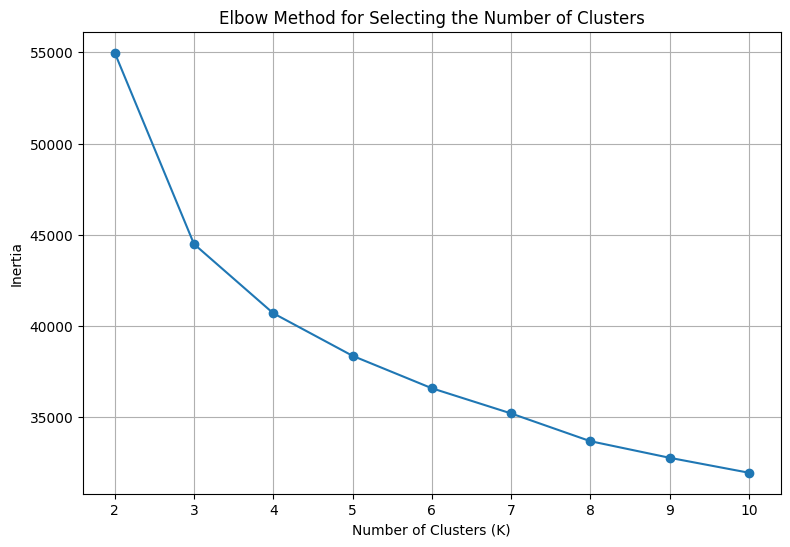

In [34]:
# ============================================================
# STEP 15: ELBOW METHOD FOR OPTIMAL NUMBER OF CLUSTERS
# ============================================================

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Define the range of cluster numbers that we want to test.
# Testing several values allows us to observe where the
# reduction in inertia begins to slow down.

k_values = range(2, 11)

# Create an empty list to store the inertia value
# for each tested number of clusters.

inertia_values = []

# Train a separate K-Means model for each value of K.
# random_state ensures that the results are reproducible.

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the K-Means model using the prepared clustering data.

    kmeans.fit(clustering_data)

    # Store the model's inertia value.

    inertia_values.append(kmeans.inertia_)

# Display the inertia values for reference.

print("Inertia values:")

for k, inertia in zip(k_values, inertia_values):
    print(f"K = {k}: Inertia = {inertia:.2f}")

# ============================================================
# CREATE ELBOW PLOT
# ============================================================

# Plot the number of clusters against their corresponding
# inertia values.

plt.figure(figsize=(9, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

# Add labels and a title to make the chart clear.

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Selecting the Number of Clusters')

# Display the integer values of K along the x-axis.

plt.xticks(list(k_values))

# Add a grid to make the elbow point easier to identify.

plt.grid(True)

plt.show()

# K-Means Clustering Model

In [35]:
# ============================================================
# STEP 16: TRAIN FINAL K-MEANS CLUSTERING MODEL
# ============================================================

from sklearn.cluster import KMeans

# Set the number of clusters based on the elbow method.
# The elbow analysis indicated that K = 4 provides a suitable
# balance between reducing within-cluster variation and
# avoiding unnecessary additional clusters.

optimal_k = 4

# Create the final K-Means clustering model.
# random_state ensures that the clustering results are
# reproducible.
# n_init=10 runs K-Means multiple times with different
# initial centroid positions and keeps the best result.

kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train the K-Means model using the prepared clustering data.

kmeans_model.fit(clustering_data)

# Assign each customer to its nearest cluster.

cluster_labels = kmeans_model.labels_

# Add the cluster assignment to a copy of the clustering data.
# This allows us to analyse the characteristics of each segment.

clustered_data = clustering_data.copy()

clustered_data['Cluster'] = cluster_labels

# Display the number of customers assigned to each cluster.

print("Number of customers in each cluster:")

print(
    clustered_data['Cluster']
    .value_counts()
    .sort_index()
)

# Display the final model inertia.

print("\nFinal K-Means inertia:")
print(round(kmeans_model.inertia_, 2))

Number of customers in each cluster:
Cluster
0     738
1    1214
2    1605
3    2077
Name: count, dtype: int64

Final K-Means inertia:
40690.91


In [36]:
# ============================================================
# VERIFY CLUSTER ASSIGNMENTS
# ============================================================

# Check that every customer has been assigned to exactly
# one of the four clusters.

print("Unique cluster labels:")
print(sorted(clustered_data['Cluster'].unique()))

# Check the total number of clustered customers.

print("\nTotal customers clustered:")
print(len(clustered_data))

# Display the first five cluster assignments.

print("\nFirst five cluster assignments:")

display(
    clustered_data[['Cluster']].head()
)

Unique cluster labels:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3)]

Total customers clustered:
5634

First five cluster assignments:


,Cluster
3738,3
3151,3
4860,3
3867,3
3810,3


# Cluster Visualisation

Explained variance ratio:
Principal Component 1: 0.2732
Principal Component 2: 0.1797

Total variance explained by the two components: 0.4529


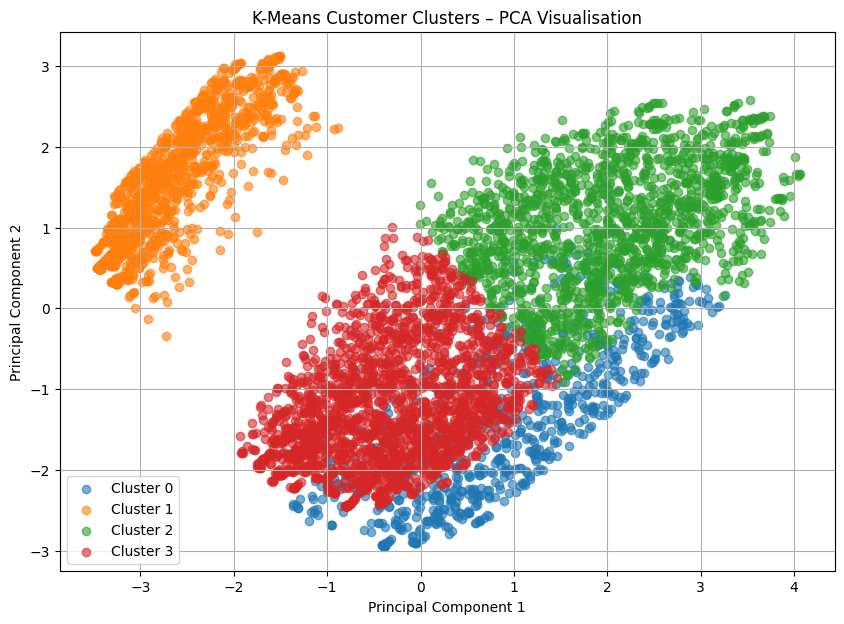

In [37]:
# ============================================================
# STEP 17: VISUALISE K-MEANS CLUSTERS USING PCA
# ============================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Create a PCA object that reduces the 45 clustering features
# to two principal components for visualisation.

pca = PCA(
    n_components=2,
    random_state=42
)

# Transform the clustering data from 45 dimensions into
# two principal components.

pca_data = pca.fit_transform(clustering_data)

# Create a DataFrame containing the two principal components
# and the corresponding K-Means cluster assignment.

pca_df = pd.DataFrame(
    pca_data,
    columns=['Principal Component 1', 'Principal Component 2'],
    index=clustering_data.index
)

# Add the K-Means cluster labels to the PCA DataFrame.

pca_df['Cluster'] = cluster_labels

# Display the explained variance of each principal component.
# This tells us how much variation in the original data is
# represented by each component.

print("Explained variance ratio:")

print(
    "Principal Component 1:",
    round(pca.explained_variance_ratio_[0], 4)
)

print(
    "Principal Component 2:",
    round(pca.explained_variance_ratio_[1], 4)
)

print(
    "\nTotal variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# ============================================================
# CREATE THE CLUSTER VISUALISATION
# ============================================================

plt.figure(figsize=(10, 7))

# Plot each cluster separately so that the customer segments
# can be visually distinguished.

for cluster in sorted(pca_df['Cluster'].unique()):

    cluster_points = pca_df[
        pca_df['Cluster'] == cluster
    ]

    plt.scatter(
        cluster_points['Principal Component 1'],
        cluster_points['Principal Component 2'],
        label=f'Cluster {cluster}',
        alpha=0.6
    )

# Add chart title and axis labels.

plt.title('K-Means Customer Clusters – PCA Visualisation')

plt.xlabel('Principal Component 1')

plt.ylabel('Principal Component 2')

# Display the cluster legend.

plt.legend()

# Add a grid to make the chart easier to interpret.

plt.grid(True)

plt.show()

In [38]:
# ============================================================
# STEP 18: CREATE CUSTOMER-LEVEL CLUSTER PROFILE DATA
# ============================================================

# Create a copy of the original cleaned dataset.
# This allows us to analyse the clusters using the original
# customer attributes rather than the encoded feature values.

cluster_profile_df = clean_df.copy()

# Add the K-Means cluster assignment to each customer.
# The clustering data uses the same original dataframe index,
# so the labels can be aligned with the corresponding customers.

cluster_profile_df['Cluster'] = pd.Series(
    cluster_labels,
    index=clustering_data.index
)

# Display the number of customers in each cluster.

print("Customer count by cluster:")

cluster_counts = (
    cluster_profile_df['Cluster']
    .value_counts()
    .sort_index()
)

display(cluster_counts)

# Calculate the percentage of customers in each cluster.

cluster_percentages = (
    cluster_counts /
    len(cluster_profile_df) * 100
).round(2)

print("\nPercentage of customers in each cluster:")

display(cluster_percentages)

Customer count by cluster:


,count
Cluster,
0.0,738
1.0,1214
2.0,1605
3.0,2077



Percentage of customers in each cluster:


,count
Cluster,
0.0,10.48
1.0,17.24
2.0,22.79
3.0,29.49


In [39]:
# ============================================================
# STEP 19: COMPARE NUMERICAL CHARACTERISTICS BY CLUSTER
# ============================================================

# Calculate the average numerical characteristics for each
# customer cluster.

numerical_cluster_profile = (
    cluster_profile_df
    .groupby('Cluster')[
        ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
    ]
    .mean()
    .round(2)
)

print("Average numerical characteristics by cluster:")

display(numerical_cluster_profile)

Average numerical characteristics by cluster:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
Cluster,,,,
0.0,1.00,26.78,79.51,2209.09
1.0,0.03,30.22,21.11,657.12
2.0,0.09,58.57,89.53,5243.79
3.0,0.00,15.68,66.35,1015.95


In [40]:
# ============================================================
# STEP 20: CALCULATE CHURN RATE BY CLUSTER
# ============================================================

# Calculate the percentage of customers who churned within
# each K-Means cluster.

churn_by_cluster = (
    cluster_profile_df
    .groupby('Cluster')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .round(2)
)

print("Churn rate by cluster (%):")

display(churn_by_cluster)

Churn rate by cluster (%):


,Churn
Cluster,
0.0,48.51
1.0,7.25
2.0,13.33
3.0,40.20


In [41]:
# ============================================================
# STEP 22: INTERNET SERVICE DISTRIBUTION BY CLUSTER
# ============================================================

# Calculate the percentage distribution of internet service
# types within each customer cluster.

internet_distribution = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['InternetService'],
    normalize='index'
).mul(100).round(2)

print("Internet service distribution within each cluster (%):")

display(internet_distribution)

Internet service distribution within each cluster (%):


InternetService,DSL,Fiber optic,No
Cluster,,,
0.0,24.25,75.75,0.0
1.0,0.00,0.00,100.0
2.0,40.31,59.69,0.0
3.0,53.49,46.51,0.0


In [42]:
# ============================================================
# STEP 21: CONTRACT DISTRIBUTION BY CLUSTER
# ============================================================

# Calculate the percentage distribution of contract types
# within each customer cluster.
#
# This helps us understand whether particular customer
# segments are mainly month-to-month, one-year, or
# two-year contract customers.

contract_distribution = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['Contract'],
    normalize='index'
).mul(100).round(2)

print("Contract distribution within each cluster (%):")

display(contract_distribution)

Contract distribution within each cluster (%):


Contract,Month-to-month,One year,Two year
Cluster,,,
0.0,84.96,12.06,2.98
1.0,34.76,23.48,41.76
2.0,19.44,33.02,47.54
3.0,83.82,12.95,3.23


In [43]:
# ============================================================
# STEP 22: PAYMENT METHOD DISTRIBUTION BY CLUSTER
# ============================================================

# Calculate the percentage distribution of payment methods
# within each customer cluster.

payment_distribution = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['PaymentMethod'],
    normalize='index'
).mul(100).round(2)

print("Payment method distribution within each cluster (%):")

display(payment_distribution)

Payment method distribution within each cluster (%):


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Cluster,,,,
0.0,16.53,15.04,60.16,8.27
1.0,21.83,21.66,7.50,49.01
2.0,33.77,32.02,25.67,8.54
3.0,15.17,15.65,45.45,23.74


In [44]:
# ============================================================
# STEP 23: SERVICE CHARACTERISTICS BY CLUSTER
# ============================================================

# List the key service-related variables that we want
# to compare between customer clusters.

service_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport'
]

# Calculate the most common value for each service within
# every customer cluster.

for column in service_columns:

    print(f"\n{column} distribution by cluster (%):")

    distribution = pd.crosstab(
        cluster_profile_df['Cluster'],
        cluster_profile_df[column],
        normalize='index'
    ).mul(100).round(2)

    display(distribution)


OnlineSecurity distribution by cluster (%):


OnlineSecurity,No,No internet service,Yes
Cluster,,,
0.0,79.81,0.0,20.19
1.0,0.00,100.0,0.00
2.0,42.31,0.0,57.69
3.0,73.62,0.0,26.38



OnlineBackup distribution by cluster (%):


OnlineBackup,No,No internet service,Yes
Cluster,,,
0.0,63.28,0.0,36.72
1.0,0.00,100.0,0.00
2.0,30.22,0.0,69.78
3.0,71.74,0.0,28.26



DeviceProtection distribution by cluster (%):


DeviceProtection,No,No internet service,Yes
Cluster,,,
0.0,64.36,0.0,35.64
1.0,0.00,100.0,0.00
2.0,27.66,0.0,72.34
3.0,74.77,0.0,25.23



TechSupport distribution by cluster (%):


TechSupport,No,No internet service,Yes
Cluster,,,
0.0,84.55,0.0,15.45
1.0,0.00,100.0,0.00
2.0,38.07,0.0,61.93
3.0,73.95,0.0,26.05


In [45]:
# ============================================================
# STEP 24: CONTRACT DISTRIBUTION BY CLUSTER
# ============================================================

# Calculate the percentage distribution of contract types
# within each customer cluster.
#
# This helps identify whether clusters differ in their
# contract commitments, such as month-to-month, one-year,
# or two-year contracts.

contract_distribution = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['Contract'],
    normalize='index'
).mul(100).round(2)

print("Contract distribution within each cluster (%):")

display(contract_distribution)

Contract distribution within each cluster (%):


Contract,Month-to-month,One year,Two year
Cluster,,,
0.0,84.96,12.06,2.98
1.0,34.76,23.48,41.76
2.0,19.44,33.02,47.54
3.0,83.82,12.95,3.23


# Payment Method

In [46]:
# ============================================================
# STEP 25: PAYMENT METHOD DISTRIBUTION BY CLUSTER
# ============================================================

# Calculate the percentage distribution of payment methods
# within each customer cluster.
#
# This helps identify differences in payment behaviour
# between the customer segments.

payment_distribution = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['PaymentMethod'],
    normalize='index'
).mul(100).round(2)

print("Payment method distribution within each cluster (%):")

display(payment_distribution)

Payment method distribution within each cluster (%):


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Cluster,,,,
0.0,16.53,15.04,60.16,8.27
1.0,21.83,21.66,7.50,49.01
2.0,33.77,32.02,25.67,8.54
3.0,15.17,15.65,45.45,23.74


# Contract Distribution

In [47]:
# ============================================================
# STEP 24: CONTRACT DISTRIBUTION BY CLUSTER
# ============================================================

# Calculate the percentage distribution of contract types
# within each customer cluster.
#
# This helps identify whether the customer segments differ
# in their contract commitment.

contract_distribution = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['Contract'],
    normalize='index'
).mul(100).round(2)

print("Contract distribution within each cluster (%):")

display(contract_distribution)

Contract distribution within each cluster (%):


Contract,Month-to-month,One year,Two year
Cluster,,,
0.0,84.96,12.06,2.98
1.0,34.76,23.48,41.76
2.0,19.44,33.02,47.54
3.0,83.82,12.95,3.23


# Final Cluster Profile Summary

In [48]:
# ============================================================
# STEP 26: FINAL CLUSTER PROFILE SUMMARY
# ============================================================

# Calculate the average numerical characteristics for each cluster.

cluster_numeric = (
    cluster_profile_df
    .groupby('Cluster')[
        ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
    ]
    .mean()
)

# Calculate the churn rate for each cluster.

cluster_churn = (
    cluster_profile_df
    .groupby('Cluster')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

# Calculate the number of customers in each cluster.

cluster_size = (
    cluster_profile_df['Cluster']
    .value_counts()
    .sort_index()
)

# Calculate the percentage of customers in each cluster.

cluster_size_percentage = (
    cluster_size / len(cluster_profile_df) * 100
)

# Create a summary DataFrame containing the main numerical
# characteristics of each customer segment.

cluster_summary = pd.DataFrame({
    'Customers': cluster_size,
    'Customer Percentage': cluster_size_percentage,
    'Average Tenure (Months)': cluster_numeric['tenure'],
    'Average Monthly Charges': cluster_numeric['MonthlyCharges'],
    'Average Total Charges': cluster_numeric['TotalCharges'],
    'Churn Rate (%)': cluster_churn
})

# Round the values to make the table easier to read.

cluster_summary = cluster_summary.round(2)

print("Final Cluster Profile Summary:")

display(cluster_summary)

Final Cluster Profile Summary:


,Customers,Customer Percentage,Average Tenure (Months),Average Monthly Charges,Average Total Charges,Churn Rate (%)
Cluster,,,,,,
0.0,738,10.48,26.78,79.51,2209.09,48.51
1.0,1214,17.24,30.22,21.11,657.12,7.25
2.0,1605,22.79,58.57,89.53,5243.79,13.33
3.0,2077,29.49,15.68,66.35,1015.95,40.20


In [49]:
# ============================================================
# STEP 27: IDENTIFY DOMINANT CUSTOMER CHARACTERISTICS
# ============================================================

# Create a function that identifies the most common category
# within each cluster for a specified categorical variable.

def get_dominant_category(data, column):

    return (
        data.groupby('Cluster')[column]
        .agg(lambda x: x.value_counts().idxmax())
    )

# Identify the most common category for important customer
# characteristics.

dominant_contract = get_dominant_category(
    cluster_profile_df,
    'Contract'
)

dominant_internet = get_dominant_category(
    cluster_profile_df,
    'InternetService'
)

dominant_payment = get_dominant_category(
    cluster_profile_df,
    'PaymentMethod'
)

# Combine the dominant characteristics into a single table.

dominant_characteristics = pd.DataFrame({
    'Dominant Contract': dominant_contract,
    'Dominant Internet Service': dominant_internet,
    'Dominant Payment Method': dominant_payment
})

print("Dominant characteristics by cluster:")

display(dominant_characteristics)

Dominant characteristics by cluster:


,Dominant Contract,Dominant Internet Service,Dominant Payment Method
Cluster,,,
0.0,Month-to-month,Fiber optic,Electronic check
1.0,Two year,No,Mailed check
2.0,Two year,Fiber optic,Bank transfer (automatic)
3.0,Month-to-month,DSL,Electronic check


In [50]:
# ============================================================
# STEP 28: CHURN COUNT AND RATE BY CLUSTER
# ============================================================

# Create a cross-tabulation showing the number of customers
# who churned and did not churn in each cluster.

churn_counts = pd.crosstab(
    cluster_profile_df['Cluster'],
    cluster_profile_df['Churn']
)

# Add the total number of customers in each cluster.

churn_counts['Total Customers'] = churn_counts.sum(axis=1)

# Calculate the percentage of customers who churned
# within each cluster.

churn_counts['Churn Rate (%)'] = (
    churn_counts['Yes'] /
    churn_counts['Total Customers'] * 100
).round(2)

print("Churn profile by cluster:")

display(churn_counts)

Churn profile by cluster:


Churn,No,Yes,Total Customers,Churn Rate (%)
Cluster,,,,
0.0,380,358,738,48.51
1.0,1126,88,1214,7.25
2.0,1391,214,1605,13.33
3.0,1242,835,2077,40.20


# Actionable Customer Segmentation Insights

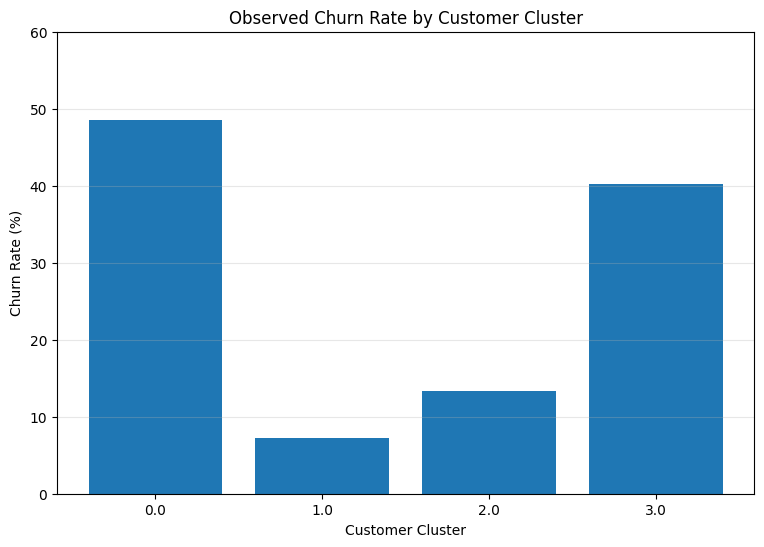

In [51]:
# ============================================================
# STEP 29: VISUALISE CHURN RATE BY CUSTOMER CLUSTER
# ============================================================

# Convert the churn rate series into a DataFrame for plotting.

churn_plot_df = churn_by_cluster.reset_index()

# Rename the columns to make the chart easier to understand.

churn_plot_df.columns = [
    'Cluster',
    'Churn Rate'
]

# Create a bar chart comparing the observed churn rate
# across the four customer clusters.

plt.figure(figsize=(9, 6))

plt.bar(
    churn_plot_df['Cluster'].astype(str),
    churn_plot_df['Churn Rate']
)

plt.xlabel('Customer Cluster')
plt.ylabel('Churn Rate (%)')
plt.title('Observed Churn Rate by Customer Cluster')

plt.ylim(0, 60)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.show()

In [62]:
# ============================================================
# STEP 37: CREATE COMPLETE GITHUB-READY PROJECT STRUCTURE
# ============================================================

import os
import shutil

# ------------------------------------------------------------
# 1. DEFINE PROJECT LOCATIONS
# ------------------------------------------------------------

# Main ACS folder in Google Drive.
acs_path = '/content/drive/MyDrive/ACS'

# This is the folder that will eventually be uploaded to GitHub.
github_project_path = os.path.join(
    acs_path,
    'Customer-Churn-Analysis-Team-9'
)

# Existing Data Preparation folder.
source_data_prep = os.path.join(
    acs_path,
    'Data_Preparation'
)

# Existing Clustering Analysis folder.
source_clustering = os.path.join(
    acs_path,
    'Clustering_Analysis'
)

# Existing Colab notebook.
notebook_source = os.path.join(
    acs_path,
    'Stage_2_Data_Preparation_and_Clustering.ipynb'
)


# ------------------------------------------------------------
# 2. CREATE GITHUB FOLDER STRUCTURE
# ------------------------------------------------------------

github_data_prep = os.path.join(
    github_project_path,
    'Data_Preparation'
)

github_clustering = os.path.join(
    github_project_path,
    'Clustering_Analysis'
)

github_notebooks = os.path.join(
    github_project_path,
    'Notebooks'
)

# Create all required folders.

os.makedirs(github_data_prep, exist_ok=True)
os.makedirs(github_clustering, exist_ok=True)
os.makedirs(github_notebooks, exist_ok=True)


# ------------------------------------------------------------
# 3. COPY DATA PREPARATION FILES
# ------------------------------------------------------------

data_prep_files = [
    'Telco_Customer_Churn_Cleaned.csv',
    'training_set_preprocessed.csv',
    'testing_set_preprocessed.csv',
    'Data_Preparation_Documentation.md',
    'Scaling_Techniques_Documentation.docx'
]

print("DATA PREPARATION FILES")
print("=" * 60)

for filename in data_prep_files:

    source = os.path.join(
        source_data_prep,
        filename
    )

    destination = os.path.join(
        github_data_prep,
        filename
    )

    # Check that the source file exists before copying.

    if os.path.exists(source):

        shutil.copy2(
            source,
            destination
        )

        print("✓ Copied:", filename)

    else:

        print("✗ MISSING:", filename)


# ------------------------------------------------------------
# 4. COPY CLUSTERING ANALYSIS FILES
# ------------------------------------------------------------

clustering_files = [
    'kmeans_model.pkl',
    'clustered_customer_data.csv',
    'elbow_method.png',
    'cluster_visualisation_pca.png',
    'Clustering_Analysis_Documentation.md'
]

print("\nCLUSTERING ANALYSIS FILES")
print("=" * 60)

for filename in clustering_files:

    source = os.path.join(
        source_clustering,
        filename
    )

    destination = os.path.join(
        github_clustering,
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            destination
        )

        print("✓ Copied:", filename)

    else:

        print("✗ MISSING:", filename)


# ------------------------------------------------------------
# 5. COPY COLAB NOTEBOOK
# ------------------------------------------------------------

print("\nNOTEBOOK")
print("=" * 60)

notebook_destination = os.path.join(
    github_notebooks,
    'Stage_2_Data_Preparation_and_Clustering.ipynb'
)

if os.path.exists(notebook_source):

    shutil.copy2(
        notebook_source,
        notebook_destination
    )

    print("✓ Copied notebook")

else:

    print("✗ Notebook not found")


# ------------------------------------------------------------
# 6. CREATE README
# ------------------------------------------------------------

readme_content = """# Customer Churn Analysis – Team 9

## Project Overview

This project analyses customer churn using the Telco Customer Churn dataset.

The overall project concept is to:

1. Prepare and clean the customer data.
2. Analyse customer characteristics and churn patterns.
3. Segment customers using K-Means clustering.
4. Develop predictive churn modelling.
5. Develop data-driven retention recommendations.

This repository contains the Stage 2 Data Preparation and Clustering Analysis deliverables.

---

## Dataset

The project uses the Telco Customer Churn dataset.

The original dataset contains:

- 7,043 customer records
- 21 columns
- Customer demographic information
- Account and contract information
- Service information
- Monthly and total charges
- Churn status

---

# Stage 2 – Data Preparation and Modeling

## Data Preparation

The data preparation process included:

- Data quality assessment
- Missing-value checking
- Blank-value checking
- Duplicate checking
- Categorical variable encoding
- Training/testing split
- Numerical feature scaling

The original dataset contained 11 blank values in TotalCharges. Investigation showed that these records had zero tenure and no churn, so the blank TotalCharges values were treated as zero.

After cleaning:

- Missing values: 0
- Duplicate customer IDs: 0
- Completely duplicated rows: 0

The cleaned dataset was divided into:

- Training set: 5,634 customers
- Testing set: 1,409 customers

After categorical encoding, 45 processed features were produced.

StandardScaler was applied to the numerical variables:

- SeniorCitizen
- tenure
- MonthlyCharges
- TotalCharges

---

# Clustering Analysis

K-Means clustering was used to identify distinct customer segments.

## Elbow Method

The elbow method was used to evaluate different values of K.

Based on the analysis, K = 4 was selected because the reduction in inertia becomes less pronounced after four clusters.

## K-Means Model

The final model used:

- Number of clusters: 4
- Random state: 42
- n_init: 10

## Cluster Sizes

| Cluster | Customers | Percentage |
|---|---:|---:|
| Cluster 0 | 738 | 10.48% |
| Cluster 1 | 1,214 | 17.24% |
| Cluster 2 | 1,605 | 22.79% |
| Cluster 3 | 2,077 | 29.49% |

## Observed Churn Rates

| Cluster | Observed Churn Rate |
|---|---:|
| Cluster 0 | 48.51% |
| Cluster 1 | 7.25% |
| Cluster 2 | 13.33% |
| Cluster 3 | 40.20% |

These are descriptive observations from the dataset and do not establish causal relationships.

---

# PCA Visualisation

PCA was used to reduce the 45-dimensional clustering dataset to two dimensions for visualisation.

Results:

- Principal Component 1: 27.32% variance explained
- Principal Component 2: 17.97% variance explained
- Combined variance explained: 45.29%

---

# Repository Structure

```text
Customer-Churn-Analysis-Team-9/
│
├── README.md
│
├── Data_Preparation/
│   ├── Telco_Customer_Churn_Cleaned.csv
│   ├── training_set_preprocessed.csv
│   ├── testing_set_preprocessed.csv
│   ├── Data_Preparation_Documentation.md
│   └── Scaling_Techniques_Documentation.docx
│
├── Clustering_Analysis/
│   ├── kmeans_model.pkl
│   ├── clustered_customer_data.csv
│   ├── elbow_method.png
│   ├── cluster_visualisation_pca.png
│   └── Clustering_Analysis_Documentation.md
│
└── Notebooks/
    └── Stage_2_Data_Preparation_and_Clustering.ipynb

_IncompleteInputError: incomplete input (3484862921.py, line 180)